# Commodity Price Forecasting AI Agent
## Notebook 02 - Data Cleaning & Exploratory Data Analysis (EDA)

### Objective
This notebook performs data cleaning, exploratory data analysis (EDA), and prepares the datasets for feature engineering and predictive modeling.

**Project:** Project 1D

**Author:** Ananya Bivare

**Date:** July 2026

In [1]:
# =====================================================
# Import Required Libraries
# =====================================================

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

# Display Settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# =====================================================
# Load Datasets
# =====================================================

data_path = "../datasets/"

silver_daily = pd.read_csv(data_path + "silver_daily_ohlcv_2000_2025.csv")

macroeconomic = pd.read_csv(data_path + "silver_macroeconomic_monthly.csv")

futures = pd.read_csv(data_path + "silver_futures_contracts.csv")

supply_demand = pd.read_csv(data_path + "silver_supply_demand_annual.csv")

sentiment = pd.read_csv(data_path + "silver_sentiment_weekly.csv")

print("All datasets loaded successfully.")

All datasets loaded successfully.


In [4]:
# Date Conversion

#Convert date columns into datetime format to enable time-series analysis and visualization.

In [6]:
# =====================================================
# Convert Date Columns
# =====================================================

silver_daily["Date"] = pd.to_datetime(silver_daily["Date"])

macroeconomic["Date"] = pd.to_datetime(macroeconomic["Date"])

futures["Trade_Date"] = pd.to_datetime(futures["Trade_Date"])

# Correct column name
sentiment["Week_Ending"] = pd.to_datetime(sentiment["Week_Ending"])

print("✅ Date columns converted successfully.")

✅ Date columns converted successfully.


In [7]:
# =====================================================
# Duplicate Records
# =====================================================

datasets = {
    "Silver Daily": silver_daily,
    "Macroeconomic": macroeconomic,
    "Futures": futures,
    "Supply Demand": supply_demand,
    "Sentiment": sentiment
}

for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

Silver Daily: 0 duplicate rows
Macroeconomic: 0 duplicate rows
Futures: 0 duplicate rows
Supply Demand: 0 duplicate rows
Sentiment: 0 duplicate rows


In [8]:
# =====================================================
# Statistical Summary
# =====================================================

for name, df in datasets.items():
    print("\n" + "="*80)
    print(name)
    print("="*80)

    display(df.describe())


Silver Daily


,Date,Open,High,Low,Close,Adj_Close,Volume,VWAP,Returns_Pct,Log_Returns,Dollar_Change,Intraday_Range,Intraday_Range_Pct
count,6783,6783.000000,6783.000000,6783.000000,6783.000000,6783.000000,6783.000000,6783.000000,6783.000000,6783.000000,6783.000000,6783.000000,6783.000000
mean,2012-12-31 14:24:15.285272064,17.527052,17.603426,17.455197,17.527283,17.527283,71737.569365,17.528635,0.045239,0.000289,0.004683,0.148229,0.808749
min,2000-01-03 00:00:00,4.022400,4.022400,4.018300,4.018400,4.018400,15375.000000,4.019700,-8.541000,-0.089280,-2.298900,0.004200,0.100000
25%,2006-07-03 12:00:00,10.547450,10.607050,10.480750,10.553500,10.553500,46089.500000,10.543950,-1.096400,-0.011024,-0.156200,0.031600,0.234950
50%,2013-01-01 00:00:00,16.634000,16.691200,16.565600,16.604700,16.604700,65879.000000,16.626700,0.070200,0.000702,0.007600,0.077600,0.534800
75%,2019-07-02 12:00:00,24.244500,24.347400,24.103500,24.227750,24.227750,91101.500000,24.209700,1.183300,0.011764,0.175150,0.185850,1.076150
max,2025-12-31 00:00:00,48.515800,49.333300,48.515800,48.536800,48.536800,332301.000000,48.662800,7.764200,0.074776,2.542100,2.717300,11.122300
std,NaN,9.397944,9.444507,9.352822,9.397174,9.397174,34541.688463,9.397863,1.806171,0.018070,0.383069,0.196219,0.827428



Macroeconomic


,Date,Silver_Price_USD,Gold_Price_USD,Silver_Gold_Ratio,Fed_Funds_Rate,US_10Y_Yield,Real_Interest_Rate,US_CPI_Index,US_CPI_YoY_Pct,DXY_Index,Crude_Oil_WTI,VIX_Index,US_M2_Supply_Trillions,India_Repo_Rate,USD_INR,Silver_Price_INR_Per_Kg,Global_PMI,US_Unemployment_Rate,ETF_Silver_Holdings_MOz
count,312,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000
mean,2012-12-15 17:23:04.615384576,17.564423,1224.202051,69.961859,3.374583,4.900801,-0.207917,282.021474,3.582756,98.791923,58.241538,15.605224,11.925369,6.135962,65.472115,39834.750000,50.010577,5.528205,450.931090
min,2000-01-01 00:00:00,4.350000,252.560000,55.020000,1.720000,2.280000,-4.190000,169.000000,1.210000,86.510000,15.000000,9.000000,4.624000,3.690000,40.540000,5998.000000,42.000000,3.500000,0.000000
25%,2006-06-23 12:00:00,10.890000,776.292500,63.130000,2.407500,4.117500,-1.375000,215.325000,2.297500,94.432500,40.347500,11.482500,6.800000,5.820000,53.937500,19720.500000,47.700000,4.400000,302.650000
50%,2012-12-16 12:00:00,16.830000,1174.955000,70.355000,3.270000,4.885000,-0.225000,272.000000,3.590000,100.240000,57.335000,15.105000,9.876000,6.165000,65.440000,38154.500000,49.850000,5.500000,507.350000
75%,2019-06-08 12:00:00,23.940000,1645.565000,77.162500,3.990000,5.682500,0.990000,344.500000,4.790000,102.850000,75.172500,18.132500,14.558750,6.550000,77.277500,60234.500000,52.125000,6.500000,697.925000
max,2025-12-01 00:00:00,48.500000,3460.460000,84.950000,5.470000,7.740000,3.810000,435.000000,5.960000,109.630000,108.750000,70.870000,27.525000,7.810000,89.150000,97075.000000,59.200000,9.900000,941.400000
std,NaN,9.146717,649.580694,8.659312,0.927999,1.099912,1.621284,76.861967,1.409073,5.867508,23.194989,6.311604,6.488885,0.705012,13.554288,24697.444518,3.093212,1.391212,290.943723



Futures


,Trade_Date,Months_To_Expiry,Spot_Price,Futures_Price,Basis,Basis_Pct,Open_Interest,Volume,Settlement_Price,Implied_Carry_Rate_Annual
count,27390,27390.000000,27390.000000,27390.000000,27390.000000,27390.000000,27390.000000,27390.000000,27390.000000,27390.000000
mean,2015-07-03 02:24:18.926615552,4.800000,20.527326,20.610044,0.082718,0.399749,247276.492954,37248.006718,20.610001,0.997457
min,2005-01-03 00:00:00,1.000000,6.528800,6.495900,-0.850700,-2.614600,80078.000000,4227.000000,6.439200,-2.000000
25%,2010-04-02 00:00:00,2.000000,15.248800,15.311425,-0.031300,-0.173900,174820.750000,21319.000000,15.309600,-0.500000
50%,2015-07-02 12:00:00,3.000000,18.612300,18.704050,0.041800,0.231450,236990.000000,33104.000000,18.704500,1.010000
75%,2020-10-01 00:00:00,6.000000,25.580600,25.722000,0.147500,0.755750,308921.000000,48980.750000,25.720075,2.510000
max,2025-12-31 00:00:00,12.000000,48.806300,50.627700,2.081500,4.676500,499478.000000,120337.000000,50.596400,4.000000
std,NaN,3.969959,7.591587,7.627226,0.221520,0.998922,90657.366878,20545.925023,7.627576,1.731538



Supply Demand


,Year,Mine_Production_MOz,Scrap_Supply_MOz,Net_Hedging_Supply_MOz,Total_Supply_MOz,Industrial_Demand_MOz,Jewelry_Demand_MOz,Investment_Demand_MOz,Photography_Demand_MOz,Silverware_Demand_MOz,Total_Demand_MOz,Supply_Demand_Balance_MOz,Avg_Price_USD_Oz,Top_Producer_Mexico_MOz,Top_Producer_Peru_MOz,Top_Producer_China_MOz,Solar_Panel_Demand_MOz,EV_Demand_MOz,COMEX_Warehouse_Stocks_MOz,LBMA_Vault_Holdings_MOz
count,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.00000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000
mean,2012.500000,617.738462,149.476923,4.023077,785.203846,429.561538,199.742308,112.303846,50.580769,49.853846,842.05000,-56.846154,17.413077,133.984615,94.119231,77.684615,36.938462,6.492308,142.450000,928.546154
std,7.648529,27.823531,16.509447,14.373818,34.174277,64.194237,9.086261,34.938374,16.147793,7.290225,60.56485,62.551670,9.045118,12.079294,9.826781,9.110025,41.463373,9.958350,30.369738,83.799538
min,2000.000000,571.900000,111.300000,-19.800000,713.900000,351.200000,188.600000,66.400000,30.000000,37.200000,739.80000,-163.900000,4.350000,111.400000,74.200000,61.200000,0.000000,0.000000,30.800000,776.000000
25%,2006.250000,592.750000,140.950000,-7.525000,761.075000,377.525000,192.050000,87.500000,37.250000,45.575000,795.60000,-107.375000,11.375000,127.025000,85.425000,71.450000,0.000000,0.000000,129.600000,870.850000
50%,2012.500000,616.600000,148.750000,6.200000,788.350000,413.050000,199.200000,103.950000,50.250000,49.800000,835.40000,-53.550000,17.340000,134.550000,94.750000,76.500000,20.050000,0.000000,143.900000,914.850000
75%,2018.750000,645.025000,153.600000,15.975000,810.250000,474.025000,205.050000,132.175000,62.075000,55.350000,880.15000,-4.000000,22.625000,143.525000,101.625000,85.575000,69.975000,11.450000,160.875000,978.250000
max,2025.000000,660.800000,188.800000,30.000000,845.100000,560.900000,225.200000,223.900000,80.500000,66.400000,975.20000,81.200000,38.000000,153.300000,110.800000,93.300000,120.700000,31.100000,182.500000,1149.800000



Sentiment


,Week_Ending,Silver_Price_Close,CFTC_Commercial_Long,CFTC_Commercial_Short,CFTC_Commercial_Net,CFTC_NonCommercial_Long,CFTC_NonCommercial_Short,CFTC_NonCommercial_Net,CFTC_Total_Open_Interest,News_Sentiment_Score,Social_Media_Mentions,Google_Trends_Index,Put_Call_Ratio,Implied_Volatility_30D,ETF_SLV_Flow_Millions,Retail_Bullion_Premium_Pct
count,1043,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000
mean,2016-01-01 00:00:00,21.160027,70068.812081,84469.820709,-14401.008629,55300.064238,37933.575264,17366.488974,247772.272291,0.001141,340.200384,30.564717,1.151413,29.297488,0.379223,6.485455
min,2006-01-06 00:00:00,9.001800,40093.000000,50137.000000,-78901.000000,30022.000000,15029.000000,-28002.000000,154216.000000,-0.962400,33.000000,5.000000,0.501800,15.030000,-192.790000,1.000000
25%,2011-01-03 12:00:00,15.811250,54829.500000,66980.000000,-33507.500000,42393.000000,27437.000000,3913.500000,226190.500000,-0.208700,260.500000,19.000000,0.827200,21.715000,-32.775000,3.735000
50%,2016-01-01 00:00:00,19.190100,70834.000000,84141.000000,-13476.000000,55739.000000,39010.000000,17332.000000,247253.000000,-0.003500,340.000000,29.000000,1.137300,29.030000,1.090000,6.560000
75%,2020-12-28 12:00:00,26.222700,84284.500000,102026.500000,5219.000000,67641.000000,48868.000000,31494.500000,270908.500000,0.211050,418.500000,40.000000,1.485800,36.525000,34.915000,9.230000
max,2025-12-26 00:00:00,48.835300,99928.000000,119980.000000,49109.000000,79961.000000,59919.000000,63990.000000,355384.000000,0.953800,705.000000,100.000000,1.799900,44.990000,158.230000,11.990000
std,NaN,7.191762,17328.854288,20480.830070,26836.584498,14340.350951,12986.001406,19621.463620,32324.199972,0.301603,116.008402,16.110236,0.379625,8.624384,51.824107,3.221260


In [9]:
# =====================================================
# Dataset Information
# =====================================================

for name, df in datasets.items():

    print("\n")
    print("="*80)
    print(name)
    print("="*80)

    df.info()



Silver Daily
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6783 entries, 0 to 6782
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                6783 non-null   datetime64[ns]
 1   Open                6783 non-null   float64       
 2   High                6783 non-null   float64       
 3   Low                 6783 non-null   float64       
 4   Close               6783 non-null   float64       
 5   Adj_Close           6783 non-null   float64       
 6   Volume              6783 non-null   int64         
 7   VWAP                6783 non-null   float64       
 8   Returns_Pct         6783 non-null   float64       
 9   Log_Returns         6783 non-null   float64       
 10  Dollar_Change       6783 non-null   float64       
 11  Intraday_Range      6783 non-null   float64       
 12  Intraday_Range_Pct  6783 non-null   float64       
dtypes: datetime64[ns](1), float64(11)

In [10]:
# =====================================================
# Missing Value Analysis
# =====================================================

for name, df in datasets.items():

    print("\n" + "="*80)
    print(f"Missing Values - {name}")
    print("="*80)

    missing = df.isnull().sum()

    missing = missing[missing > 0]

    if len(missing) == 0:
        print("✅ No Missing Values")
    else:
        display(missing.sort_values(ascending=False))


Missing Values - Silver Daily
✅ No Missing Values

Missing Values - Macroeconomic
✅ No Missing Values

Missing Values - Futures
✅ No Missing Values

Missing Values - Supply Demand
✅ No Missing Values

Missing Values - Sentiment
✅ No Missing Values


In [11]:
# =====================================================
# Negative Value Check
# =====================================================

print("Silver Daily Dataset")

numeric_cols = silver_daily.select_dtypes(include=np.number).columns

for col in numeric_cols:

    count = (silver_daily[col] < 0).sum()

    print(f"{col:<20} : {count}")

Silver Daily Dataset
Open                 : 0
High                 : 0
Low                  : 0
Close                : 0
Adj_Close            : 0
Volume               : 0
VWAP                 : 0
Returns_Pct          : 3284
Log_Returns          : 3284
Dollar_Change        : 3284
Intraday_Range       : 0
Intraday_Range_Pct   : 0


In [12]:
# =====================================================
# Date Range
# =====================================================

print("Silver Daily")
print(silver_daily["Date"].min())
print(silver_daily["Date"].max())

print("\nMacroeconomic")
print(macroeconomic["Date"].min())
print(macroeconomic["Date"].max())

print("\nFutures")
print(futures["Trade_Date"].min())
print(futures["Trade_Date"].max())

print("\nSentiment")
print(sentiment["Week_Ending"].min())
print(sentiment["Week_Ending"].max())

Silver Daily
2000-01-03 00:00:00
2025-12-31 00:00:00

Macroeconomic
2000-01-01 00:00:00
2025-12-01 00:00:00

Futures
2005-01-03 00:00:00
2025-12-31 00:00:00

Sentiment
2006-01-06 00:00:00
2025-12-26 00:00:00


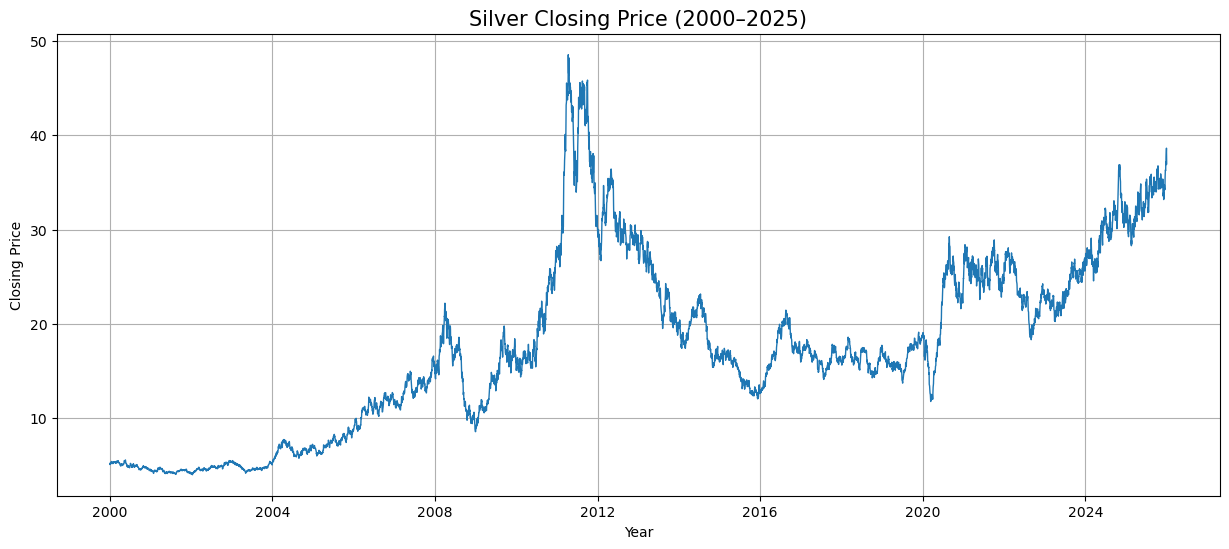

In [13]:
# =====================================================
# Silver Closing Price Trend
# =====================================================

plt.figure(figsize=(15,6))

plt.plot(
    silver_daily["Date"],
    silver_daily["Close"],
    linewidth=1
)

plt.title("Silver Closing Price (2000–2025)", fontsize=15)

plt.xlabel("Year")

plt.ylabel("Closing Price")

plt.grid(True)

plt.show()

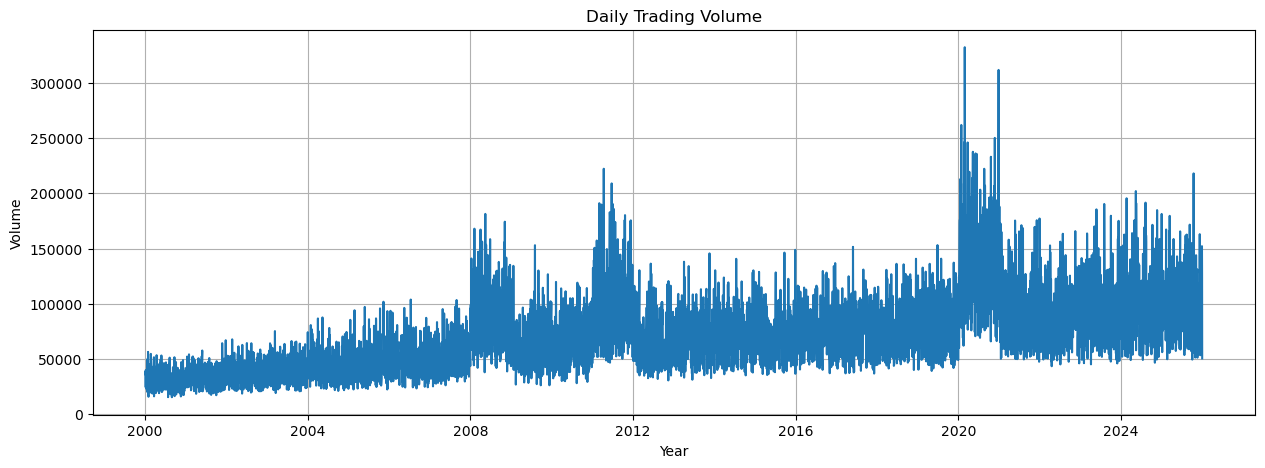

In [14]:
# =====================================================
# Trading Volume
# =====================================================

plt.figure(figsize=(15,5))

plt.plot(
    silver_daily["Date"],
    silver_daily["Volume"]
)

plt.title("Daily Trading Volume")

plt.xlabel("Year")

plt.ylabel("Volume")

plt.grid(True)

plt.show()

# Distribution of Silver Closing Prices

This histogram shows the distribution of daily silver closing prices over the historical period.

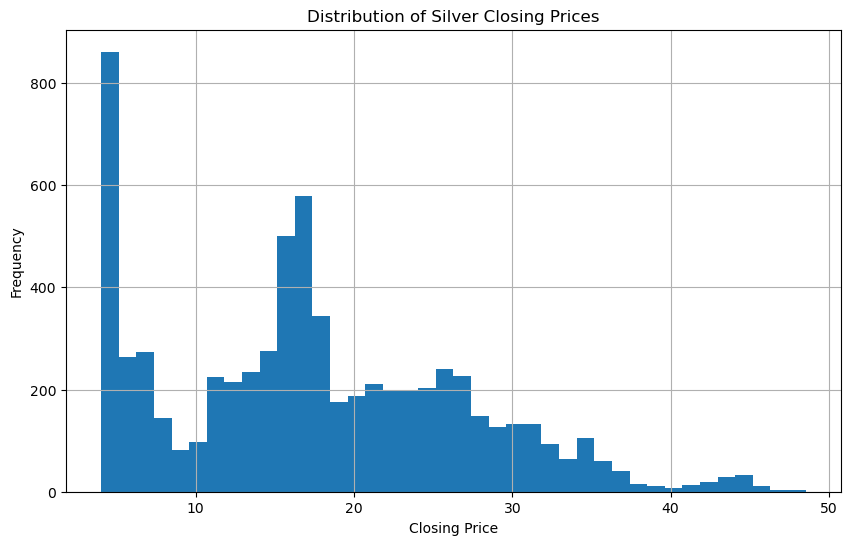

In [15]:
# =====================================================
# Distribution of Closing Prices
# =====================================================

plt.figure(figsize=(10,6))

plt.hist(silver_daily["Close"], bins=40)

plt.title("Distribution of Silver Closing Prices")

plt.xlabel("Closing Price")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

In [16]:
# =====================================================
# Daily Returns Distribution
# =====================================================

plt.figure(figsize=(10,6))

plt.hist(silver_daily["Returns"], bins=50)

plt.title("Distribution of Daily Returns")

plt.xlabel("Returns")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

KeyError: 'Returns'

<Figure size 1000x600 with 0 Axes>

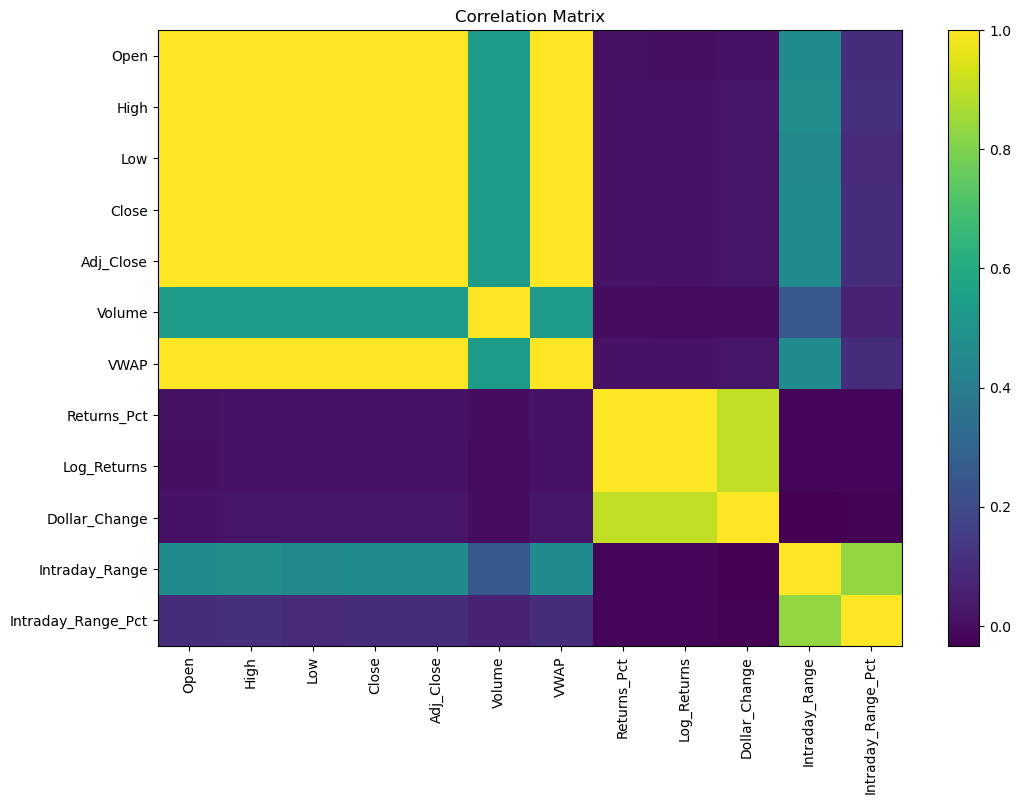

In [17]:
# =====================================================
# Correlation Matrix
# =====================================================

corr = silver_daily.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12,8))

plt.imshow(corr, aspect="auto")

plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)

plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Matrix")

plt.show()

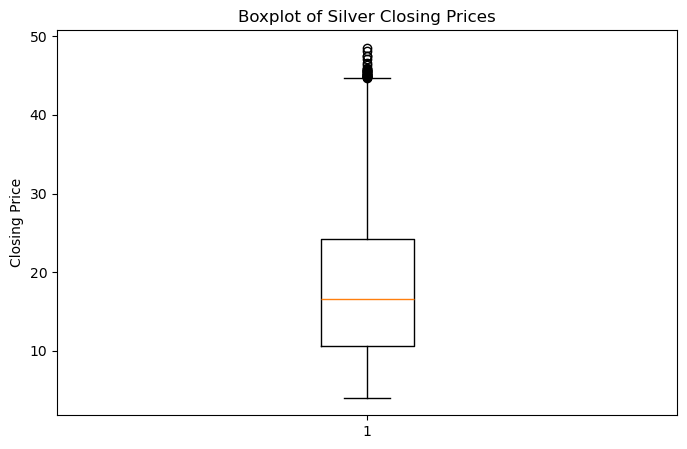

In [18]:
# =====================================================
# Closing Price Boxplot
# =====================================================

plt.figure(figsize=(8,5))

plt.boxplot(silver_daily["Close"], vert=True)

plt.title("Boxplot of Silver Closing Prices")

plt.ylabel("Closing Price")

plt.show()

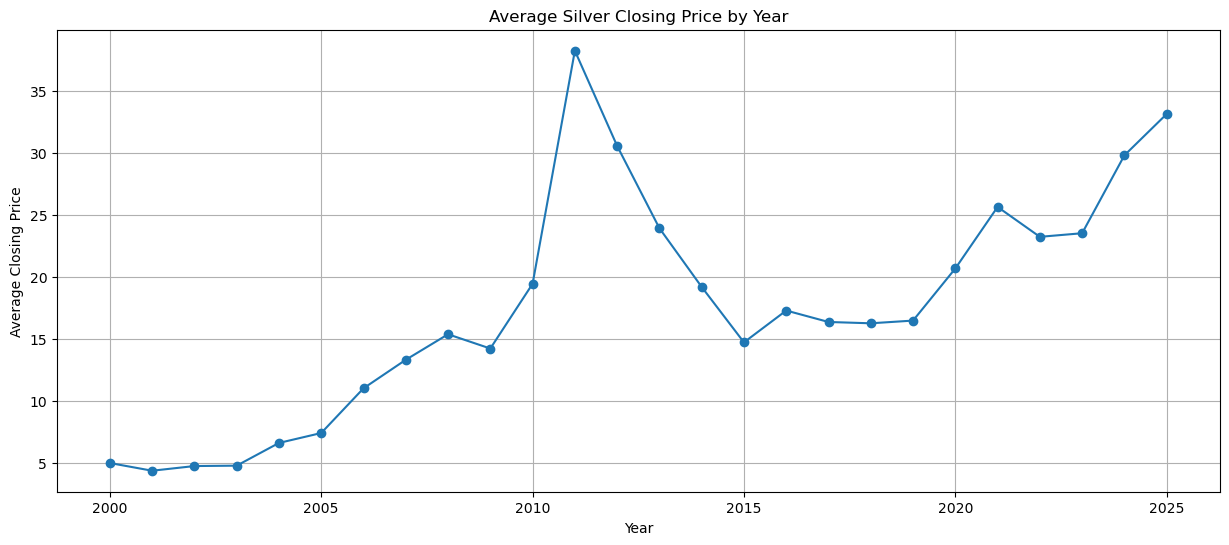

In [19]:
# =====================================================
# Year-wise Average Closing Price
# =====================================================

silver_daily["Year"] = silver_daily["Date"].dt.year

yearly_avg = silver_daily.groupby("Year")["Close"].mean()

plt.figure(figsize=(15,6))

plt.plot(yearly_avg.index, yearly_avg.values, marker="o")

plt.title("Average Silver Closing Price by Year")

plt.xlabel("Year")

plt.ylabel("Average Closing Price")

plt.grid(True)

plt.show()

In [20]:
# =====================================================
# Export Cleaned Datasets
# =====================================================

import os

os.makedirs("../outputs", exist_ok=True)

silver_daily.to_csv("../outputs/clean_silver_daily.csv", index=False)

macroeconomic.to_csv("../outputs/clean_macroeconomic.csv", index=False)

futures.to_csv("../outputs/clean_futures.csv", index=False)

supply_demand.to_csv("../outputs/clean_supply_demand.csv", index=False)

sentiment.to_csv("../outputs/clean_sentiment.csv", index=False)

print("✅ All cleaned datasets exported successfully.")

✅ All cleaned datasets exported successfully.


# Conclusion

This notebook successfully completed the data cleaning and exploratory data analysis process. The datasets were validated, inspected, and visualized. Cleaned datasets have been exported and are now ready for feature engineering and predictive modeling in the next notebook.